# Pooling Usage — Facility Only (fac=1, amb=0)

How much cross-battalion routing actually occurs under facility pooling?
Does the greedy dispatcher ever send patients to the neighbor R1?

In [22]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster" / "20260605_212356_scenario_2btg_pooling_limit_baseline_stove" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")
print(f"Columns: {df.columns.tolist()}")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

Loaded 40960 runs
Columns: ['ccp_r1_same_bn_min', 'bcas_rate', 'waves_per_day', 'wave_duration_min', 'facility_eligibility', 'ambulance_eligibility', 'scenario', 'policy', 'model', 'death_rate_T1_BCAS', 'frac_facility_cross_bn', 'frac_transport_cross_bn']


In [23]:
fac = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].reset_index(drop=True)
stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].reset_index(drop=True)
amb = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)
both = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)

print(f"Fac only: {len(fac)} runs")

if "frac_facility_cross_bn" in fac.columns:
    print(f"\nFacility cross-bn fraction:")
    print(f"  Mean:   {fac['frac_facility_cross_bn'].mean():.4f}")
    print(f"  Median: {fac['frac_facility_cross_bn'].median():.4f}")
    print(f"  Min:    {fac['frac_facility_cross_bn'].min():.4f}")
    print(f"  Max:    {fac['frac_facility_cross_bn'].max():.4f}")
    print(f"  Zero:   {(fac['frac_facility_cross_bn'] == 0).sum()} / {len(fac)} ({(fac['frac_facility_cross_bn'] == 0).mean():.1%})")
else:
    print("frac_facility_cross_bn not in results — re-run experiment with pooling fraction outcomes")

if "frac_transport_cross_bn" in fac.columns:
    print(f"\nTransport cross-bn fraction:")
    print(f"  Mean:   {fac['frac_transport_cross_bn'].mean():.4f}")
    print(f"  Median: {fac['frac_transport_cross_bn'].median():.4f}")
    print(f"  Zero:   {(fac['frac_transport_cross_bn'] == 0).sum()} / {len(fac)} ({(fac['frac_transport_cross_bn'] == 0).mean():.1%})")

Fac only: 10240 runs

Facility cross-bn fraction:
  Mean:   0.0668
  Median: 0.0625
  Min:    0.0000
  Max:    0.3824
  Zero:   2600 / 10240 (25.4%)

Transport cross-bn fraction:
  Mean:   0.0180
  Median: 0.0000
  Zero:   6102 / 10240 (59.6%)


## Pooling Usage Distribution — All 4 Policies

C:\Users\User\AppData\Local\Temp\ipykernel_1712\224994065.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data_fac, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\224994065.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_trn, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)


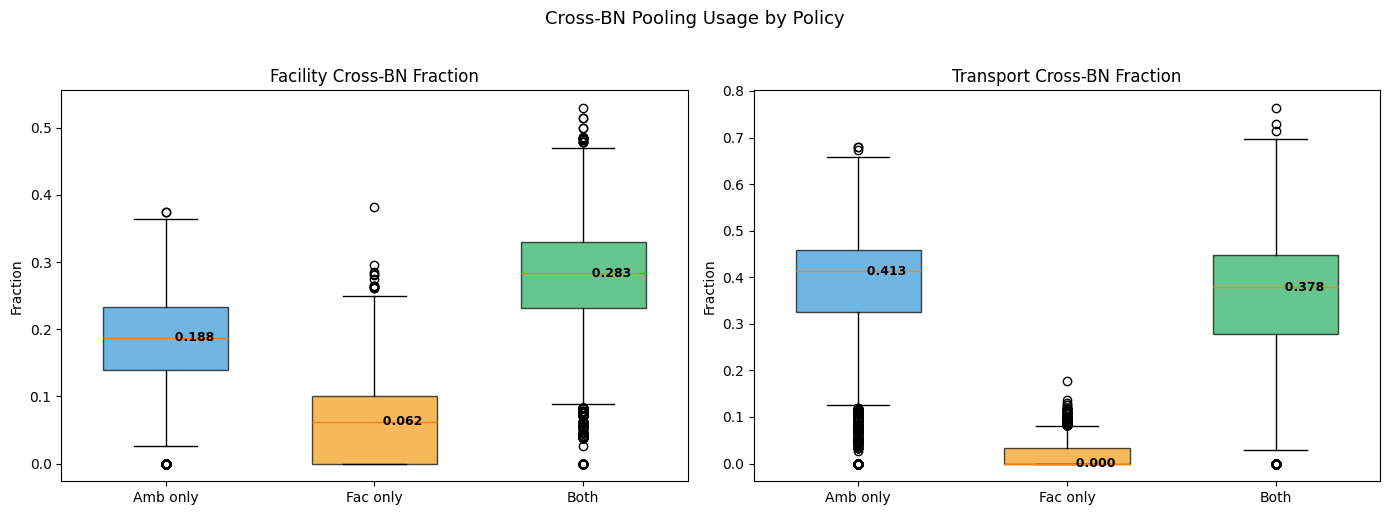

In [28]:
policies = [
    ("Amb only", amb, "#3498db"),
    ("Fac only", fac, "#f39c12"),
    ("Both", both, "#27ae60"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Facility cross-bn boxplots
data_fac = [sub["frac_facility_cross_bn"].dropna().values for _, sub, _ in policies]
bp = axes[0].boxplot(data_fac, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)
for patch, (_, _, color) in zip(bp["boxes"], policies):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data_fac):
    med = np.median(d)
    axes[0].text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Fraction")
axes[0].set_title("Facility Cross-BN Fraction")

# Transport cross-bn boxplots
data_trn = [sub["frac_transport_cross_bn"].dropna().values for _, sub, _ in policies]
bp = axes[1].boxplot(data_trn, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)
for patch, (_, _, color) in zip(bp["boxes"], policies):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data_trn):
    med = np.median(d)
    axes[1].text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
axes[1].set_ylabel("Fraction")
axes[1].set_title("Transport Cross-BN Fraction")

fig.suptitle("Cross-BN Pooling Usage by Policy", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Facility Pooling Usage vs Each Uncertainty

C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecati

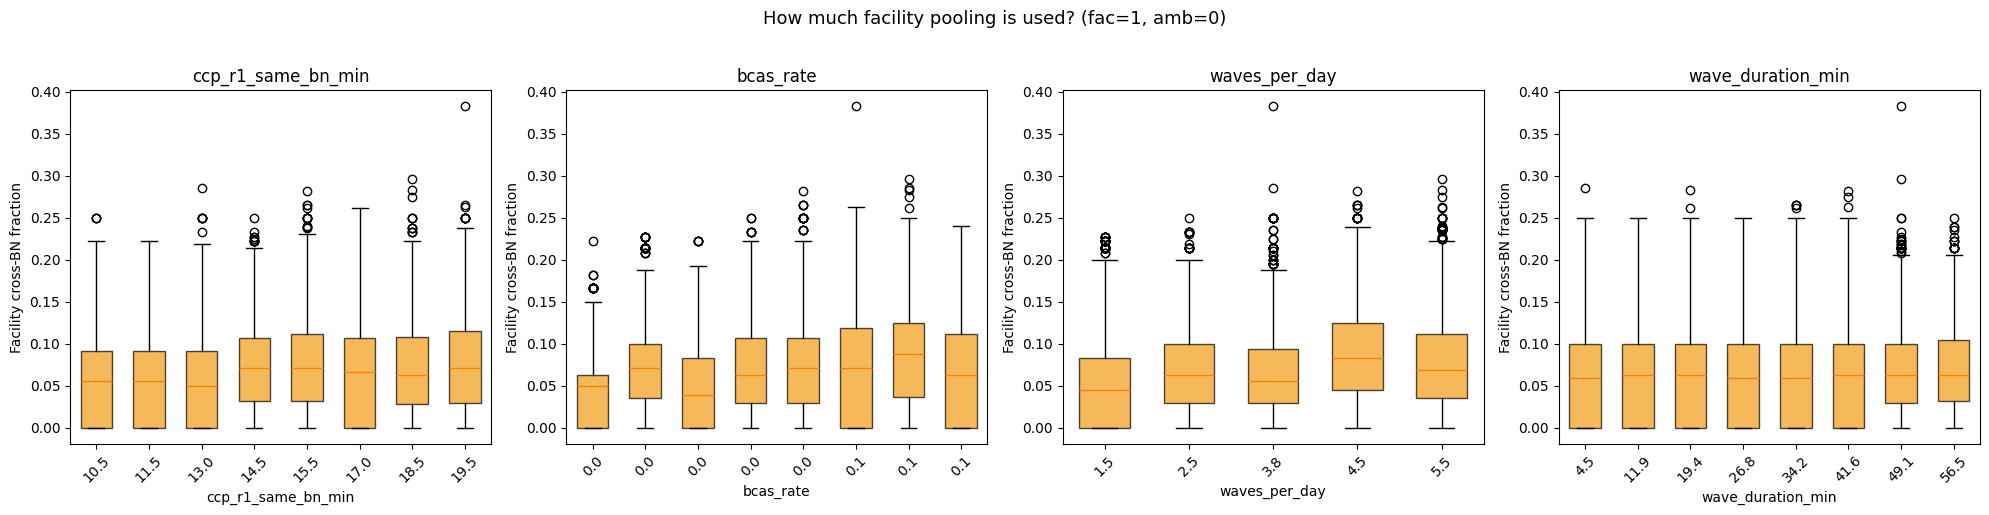

In [26]:
if "frac_facility_cross_bn" in fac.columns:
    fig, axes = plt.subplots(1, len(UNCERTAINTIES), figsize=(5 * len(UNCERTAINTIES), 5))

    for ax, col in zip(axes, UNCERTAINTIES):
        bins = pd.qcut(fac[col], q=8, duplicates="drop")
        groups = fac.groupby(bins, observed=True)
        labels = [f"{iv.mid:.1f}" for iv in groups.groups.keys()]
        data = [g["frac_facility_cross_bn"].values for _, g in groups]

        bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
        for patch in bp["boxes"]:
            patch.set_facecolor("#f39c12")
            patch.set_alpha(0.7)
        ax.set_xlabel(col)
        ax.set_ylabel("Facility cross-BN fraction")
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=45)

    fig.suptitle("How much facility pooling is used? (fac=1, amb=0)", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No frac_facility_cross_bn column.")

## Pooling Usage vs Mortality — Does more pooling help?

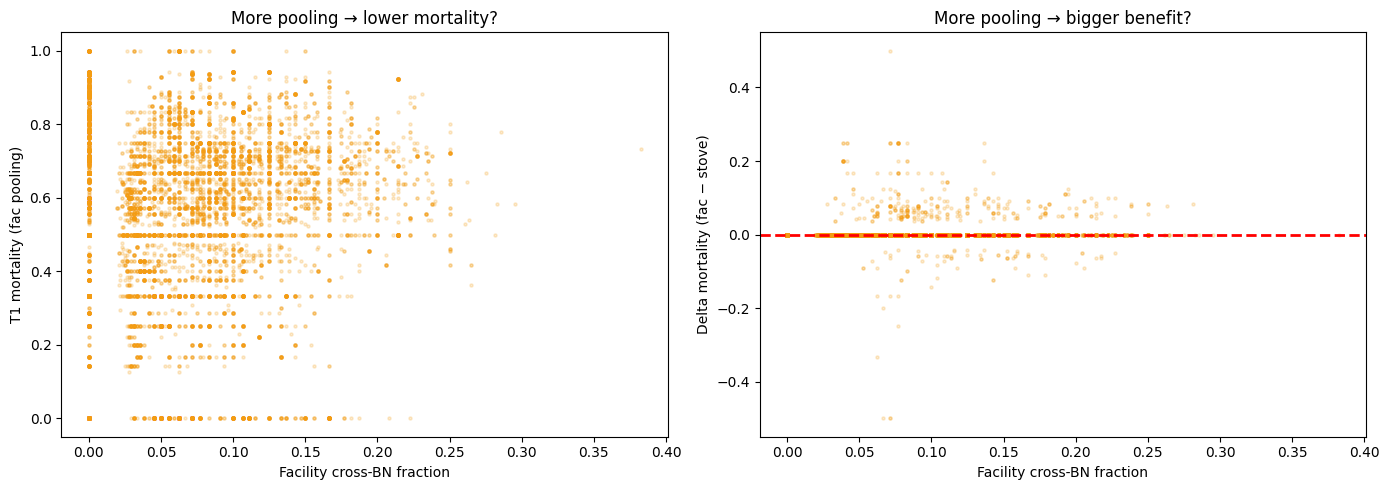

                        n  mean_mort  mean_delta  mean_pooling
pool_bin                                                      
(-0.000382, 0.0765]  6111     0.5487      0.0009        0.0288
(0.0765, 0.153]      3308     0.5868      0.0035        0.1067
(0.153, 0.229]        747     0.6064      0.0030        0.1825
(0.229, 0.306]         73     0.6113      0.0085        0.2470
(0.306, 0.382]          1     0.7333      0.0000        0.3824


In [27]:
if "frac_facility_cross_bn" in fac.columns:
    fac_sorted = fac.sort_values("scenario").reset_index(drop=True)
    stove_sorted = stove.sort_values("scenario").reset_index(drop=True)
    assert (fac_sorted["scenario"].values == stove_sorted["scenario"].values).all()

    delta = fac_sorted["death_rate_T1_BCAS"].values - stove_sorted["death_rate_T1_BCAS"].values

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Pooling usage vs mortality
    axes[0].scatter(fac_sorted["frac_facility_cross_bn"], fac_sorted["death_rate_T1_BCAS"],
                    alpha=0.2, s=5, color="#f39c12")
    axes[0].set_xlabel("Facility cross-BN fraction")
    axes[0].set_ylabel("T1 mortality (fac pooling)")
    axes[0].set_title("More pooling → lower mortality?")

    # Pooling usage vs delta
    axes[1].scatter(fac_sorted["frac_facility_cross_bn"], delta,
                    alpha=0.2, s=5, color="#f39c12")
    axes[1].axhline(0, color="red", linewidth=2, linestyle="--")
    axes[1].set_xlabel("Facility cross-BN fraction")
    axes[1].set_ylabel("Delta mortality (fac − stove)")
    axes[1].set_title("More pooling → bigger benefit?")

    plt.tight_layout()
    plt.show()

    # Summary table by pooling usage bins
    fac_sorted["delta"] = delta
    fac_sorted["pool_bin"] = pd.cut(fac_sorted["frac_facility_cross_bn"], bins=5)
    summary = fac_sorted.groupby("pool_bin", observed=True).agg(
        n=("death_rate_T1_BCAS", "count"),
        mean_mort=("death_rate_T1_BCAS", "mean"),
        mean_delta=("delta", "mean"),
        mean_pooling=("frac_facility_cross_bn", "mean"),
    )
    print(summary.to_string(float_format="%.4f"))
else:
    print("No frac_facility_cross_bn column.")